# 02 · Zonas e conduítes (IEC 62443-3-2)

**Objetivo:** dividir a planta em **zonas** (grupos de ativos com os mesmos requisitos de segurança) e definir os **conduítes** (os únicos caminhos permitidos entre zonas). Depois, confrontar o desenho com o tráfego real do exercício 01.

* **Zona:** conjunto de ativos que compartilham o mesmo nível de risco e o mesmo SL-T.
* **Conduíte:** canal de comunicação entre zonas, com regras explícitas (quem, para quem, qual porta, por quê).

A planta segue o **modelo Purdue**: nível 1 (controle), 2 (supervisão), 3 (operações do site), 3.5 (DMZ industrial) e 4 (TI corporativa). A regra de ouro: **a TI nunca fala direto com a planta, sempre pela DMZ**.

In [1]:
# Configuração: raiz do repositório no caminho de import, tabelas largas
import sys, pathlib, logging, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
from IPython.display import Image, Markdown, display
from otsec.model import CAPTURES
import yaml
from otsec import zones as z, inventory as inv, figures
from otsec.model import MODEL, FR
print((MODEL / "zones.yaml").read_text()[:2400])

# Zones and conduits in the sense of IEC 62443-3-2.
# sl_t is the target security level per foundational requirement (FR1..FR7):
#   FR1 IAC identification and authentication control, FR2 UC use control,
#   FR3 SI system integrity, FR4 DC data confidentiality,
#   FR5 RDF restricted data flow, FR6 TRE timely response to events, FR7 RA resource availability
zones:
  cell:        {purdue: 1,   name: Cell 1 control,      assets: [plc-1, plc-2],            sl_t: [2, 2, 2, 1, 2, 2, 3]}
  supervision: {purdue: 2,   name: Line supervision,    assets: [hmi-1, ews-1, scada-1],   sl_t: [2, 2, 2, 1, 2, 2, 2]}
  site_ops:    {purdue: 3,   name: Site operations,     assets: [hist-1, broker-1],        sl_t: [2, 2, 2, 2, 2, 2, 2]}
  dmz:         {purdue: 3.5, name: Industrial DMZ,      assets: [dmz-broker],              sl_t: [3, 3, 2, 2, 3, 2, 2]}
  enterprise:  {purdue: 4,   name: Enterprise IT,       assets: [office-1, erp-1],         sl_t: [1, 1, 1, 1, 1, 1, 1]}

# Every allowed flow. Anything e

## 1. O modelo como dado

Zonas e conduítes estão num YAML. Assim o desenho pode ser **versionado, revisado em PR e testado**, em vez de existir só num Visio.

In [2]:
zt = pd.DataFrame([{"zona": k, "nome": v["name"], "Purdue": v["purdue"], "ativos": ", ".join(v["assets"]),
                    **dict(zip(FR, v["sl_t"]))} for k, v in z.zones()["zones"].items()])
print("SL-T por requisito fundamental:"); zt

SL-T por requisito fundamental:


,zona,nome,Purdue,ativos,IAC,UC,SI,DC,RDF,TRE,RA
0,cell,Cell 1 control,1.0,"plc-1, plc-2",2,2,2,1,2,2,3
1,supervision,Line supervision,2.0,"hmi-1, ews-1, scada-1",2,2,2,1,2,2,2
2,site_ops,Site operations,3.0,"hist-1, broker-1",2,2,2,2,2,2,2
3,dmz,Industrial DMZ,3.5,dmz-broker,3,3,2,2,3,2,2
4,enterprise,Enterprise IT,4.0,"office-1, erp-1",1,1,1,1,1,1,1


**Leitura do SL-T:** a célula tem **RA = 3** porque disponibilidade do CLP é o que mais importa (parada de linha); a DMZ tem **IAC, UC e RDF = 3** porque é a fronteira que a TI enxerga. A TI corporativa fica em 1 para este escopo: ela tem seu próprio programa de segurança.

## 2. Regras de projeto

Antes de olhar o tráfego, o próprio desenho é verificado: todo ativo em exatamente uma zona, nenhum conduíte pulando níveis, nenhum conduíte da TI que não passe pela DMZ.

In [3]:
problemas = z.check_model()
print("problemas no desenho:", problemas or "nenhum")

problemas no desenho: nenhum


In [4]:
# o que acontece se alguém propuser um atalho da TI para a célula?
import copy
from otsec import model
original = model.zones()
ruim = copy.deepcopy(original)
ruim["conduits"].append({"id": "C9", "from": "enterprise", "to": "cell", "src": ["erp-1"], "dst": ["plc-1"], "port": 502, "why": "relatório rápido"})
z.zones = lambda: ruim  # troca temporária do modelo só para este teste
print(z.check_model())
z.zones = model.zones

['C9: enterprise must only reach the plant through the DMZ', 'C9: skips a Purdue level (4 to 1)']


O atalho é recusado por **duas** regras. É esse tipo de checagem que impede que um pedido urgente de "só um relatório" abra a planta para a TI.

## 3. Desenho contra realidade

Cada fluxo observado no exercício 01 é classificado: permitido por um conduíte, interno à zona, ou **violação**.

In [5]:
fluxos = inv.flows(inv.packets(CAPTURES / "baseline_day1.pcap"))
c = z.compliance(fluxos)
c.style.apply(lambda r: ["background-color: #fadbd8" if r.verdict == "VIOLATION" else ""] * len(r), axis=1)

,src,dst,port,service,from_zone,to_zone,verdict,reason,packets
0,erp-1,broker-1,1883,mqtt,enterprise,site_ops,VIOLATION,enterprise reaches the plant without passing through the DMZ,14
1,erp-1,dmz-broker,8883,mqtts,enterprise,dmz,allowed,conduit C6,60
2,office-1,hmi-1,3389,rdp,enterprise,supervision,VIOLATION,enterprise reaches the plant without passing through the DMZ,10
3,broker-1,dmz-broker,8883,mqtts,site_ops,dmz,allowed,conduit C5,60
4,hist-1,plc-1,502,modbus,site_ops,cell,VIOLATION,no conduit from site_ops to cell for this pair,20
5,hist-1,scada-1,4840,opcua,site_ops,supervision,allowed,conduit C3,122
6,ews-1,plc-1,502,modbus,supervision,cell,allowed,conduit C2,9
7,hmi-1,plc-1,502,modbus,supervision,cell,allowed,conduit C1,602
8,hmi-1,plc-2,502,modbus,supervision,cell,allowed,conduit C1,602
9,scada-1,broker-1,1883,mqtt,supervision,site_ops,VIOLATION,right peers but wrong port 1883 (conduit C4 allows 8883),123


**Quatro violações, cada uma com a razão:**

1. **erp-1 → broker-1 (1883)**: a TI lendo o broker da planta direto, em texto aberto. Deveria ler da réplica na DMZ (conduíte C6).
2. **office-1 → hmi-1 (3389)**: RDP do escritório para o painel do operador. É o caminho clássico de ransomware chegando na planta.
3. **hist-1 → plc-1 (502)**: o historiador lendo o CLP direto. Pela arquitetura ele lê pelo SCADA em OPC UA (C3).
4. **scada-1 → broker-1 (1883)**: os pares certos, mas na porta errada. O conduíte C4 exige 8883 (MQTT com TLS).

## 4. O desenho, com as violações em vermelho

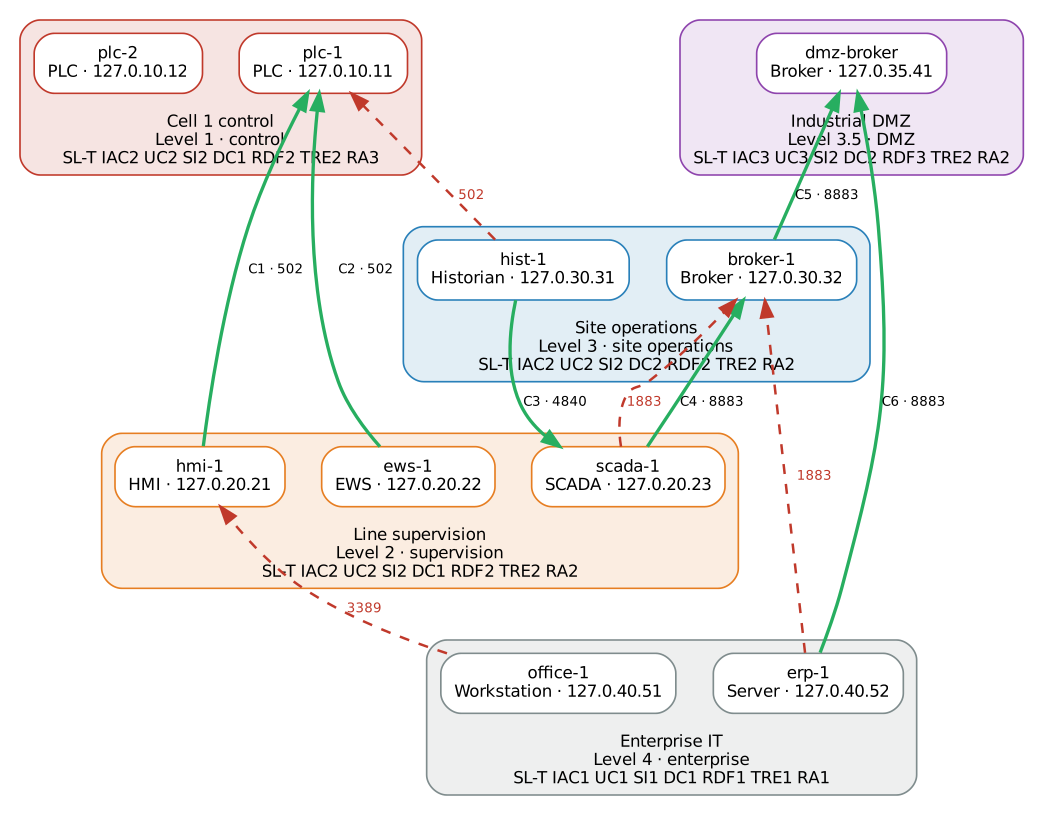

In [6]:
Image(filename=figures.render(z.dot(c), "zones_as_found"))

Verde é o que o projeto permite; vermelho tracejado é o que acontece hoje. A próxima pergunta é **quanto risco** cada caminho vermelho representa (exercício 03), e depois **fechar** esses caminhos (exercício 04).

## Resumo

* Zonas e conduítes como **código**: revisáveis, versionados e testados (`tests/test_zones.py`).
* O SL-T por FR documenta **por que** cada zona precisa de cada proteção.
* Comparar o desenho com a captura transforma "achamos que a rede é segmentada" em uma lista objetiva de desvios.